# Notebook 2: Traditional ML Models
## Naive Bayes · Logistic Regression · SVM · Random Forest · XGBoost

**Input:** `data/train.csv`, `data/val.csv`, `data/test.csv` (from Notebook 1)  
**Features:** TF-IDF (unigram + bigram)  
**Task:** 3-class sentiment classification (negative / neutral / positive)

## 0. Imports

In [ ]:
# !pip install scikit-learn xgboost matplotlib seaborn pandas numpy joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os, joblib
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import cross_val_score, StratifiedKFold
import xgboost as xgb

os.makedirs('models', exist_ok=True)
sns.set_theme(style='whitegrid')
LABEL_NAMES = ['negative', 'neutral', 'positive']
print('Imports ✓')

Imports ✓


## 1. Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ⚠️ Replace this with the actual path to your "models" folder in Drive
# Tip: in the Colab file browser, right-click the folder → "Copy path"
DRIVE_MODELS_DIR = '/content/drive/MyDrive/YOUR_PROJECT_FOLDER/data/models/Traditional_ML'

import os
os.makedirs(DRIVE_MODELS_DIR, exist_ok=True)
print(f'Models will be saved to: {DRIVE_MODELS_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models will be saved to: /content/drive/MyDrive/YOUR_PROJECT_FOLDER/data/models/Traditional_ML


In [ ]:
import pandas as pd

train_df = pd.read_csv('/content/drive/MyDrive/data/train.csv')
val_df   = pd.read_csv('/content/drive/MyDrive/data/val.csv')
test_df  = pd.read_csv('/content/drive/MyDrive/data/test.csv')

X_train, y_train = train_df['text'], train_df['label']
X_val, y_val     = val_df['text'], val_df['label']
X_test, y_test   = test_df['text'], test_df['label']

# recreate this (missing variable)
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

print(len(X_trainval), len(y_trainval))



4850 4850


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. TF-IDF Vectorizer

In [ ]:
# ── Fit TF-IDF on training data ───────────────────────────────────────────────
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # unigram + bigram
    max_features=20000,
    sublinear_tf=True,    # log(1 + tf) scaling
    min_df=2,
    analyzer='word',
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

print(f'Vocab size : {len(tfidf.vocabulary_):,}')
print(f'Train matrix: {X_train_tfidf.shape}')

# Save vectorizer
# joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')
joblib.dump(tfidf, f'{DRIVE_MODELS_DIR}/tfidf_vectorizer.pkl')
print('TF-IDF vectorizer saved ✓')

Vocab size : 8,778
Train matrix: (3994, 8778)
TF-IDF vectorizer saved ✓


## 3. Define & Train All Models

In [ ]:
# ── Model definitions ─────────────────────────────────────────────────────────
MODELS = {
    'Naive Bayes (Multinomial)': MultinomialNB(alpha=0.5),
    'Naive Bayes (Complement)' : ComplementNB(alpha=0.5),
    'Logistic Regression'      : LogisticRegression(
                                     C=5, max_iter=500, solver='lbfgs',
                                     multi_class='multinomial', random_state=42),
    'Linear SVM'               : LinearSVC(C=1.0, max_iter=1000, random_state=42),
    'Random Forest'            : RandomForestClassifier(
                                     n_estimators=200, max_depth=None,
                                     n_jobs=-1, random_state=42),
    'XGBoost'                  : xgb.XGBClassifier(
                                     n_estimators=200, learning_rate=0.1,
                                     max_depth=6, use_label_encoder=False,
                                     eval_metric='mlogloss', random_state=42,
                                     n_jobs=-1),
}

results = []

for name, model in MODELS.items():
    print(f'Training: {name} ...', end=' ')
    model.fit(X_train_tfidf, y_train)

    # Validation metrics
    y_val_pred  = model.predict(X_val_tfidf)
    y_test_pred = model.predict(X_test_tfidf)

    val_acc  = accuracy_score(y_val,  y_val_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    val_f1   = f1_score(y_val,  y_val_pred,  average='weighted')
    test_f1  = f1_score(y_test, y_test_pred, average='weighted')

    results.append({
        'Model'   : name,
        'Val Acc' : round(val_acc,  4),
        'Test Acc': round(test_acc, 4),
        'Val F1'  : round(val_f1,   4),
        'Test F1' : round(test_f1,  4),
    })

    # Save model
    safe_name = name.replace(' ', '_').replace('(', '').replace(')', '')
    # joblib.dump(model, f'models/{safe_name}.pkl')
    joblib.dump(model, f'{DRIVE_MODELS_DIR}/{safe_name}.pkl')
    print(f'Val Acc={val_acc:.4f} | Test Acc={test_acc:.4f} ✓')

results_df = pd.DataFrame(results).sort_values('Test F1', ascending=False)
print('\n=== Results ===')
results_df

Training: Naive Bayes (Multinomial) ... Val Acc=0.8072 | Test Acc=0.8084 ✓
Training: Naive Bayes (Complement) ... Val Acc=0.8107 | Test Acc=0.8341 ✓
Training: Logistic Regression ... Val Acc=0.8610 | Test Acc=0.8621 ✓
Training: Linear SVM ... Val Acc=0.8575 | Test Acc=0.8680 ✓
Training: Random Forest ... Val Acc=0.8376 | Test Acc=0.8470 ✓
Training: XGBoost ... Val Acc=0.7909 | Test Acc=0.8014 ✓

=== Results ===


,Model,Val Acc,Test Acc,Val F1,Test F1
3,Linear SVM,0.8575,0.8680,0.8577,0.8683
2,Logistic Regression,0.8610,0.8621,0.8614,0.8625
4,Random Forest,0.8376,0.8470,0.8394,0.8481
1,Naive Bayes (Complement),0.8107,0.8341,0.8119,0.8351
0,Naive Bayes (Multinomial),0.8072,0.8084,0.8084,0.8099
5,XGBoost,0.7909,0.8014,0.7916,0.8027


## 4. Comparison Plot

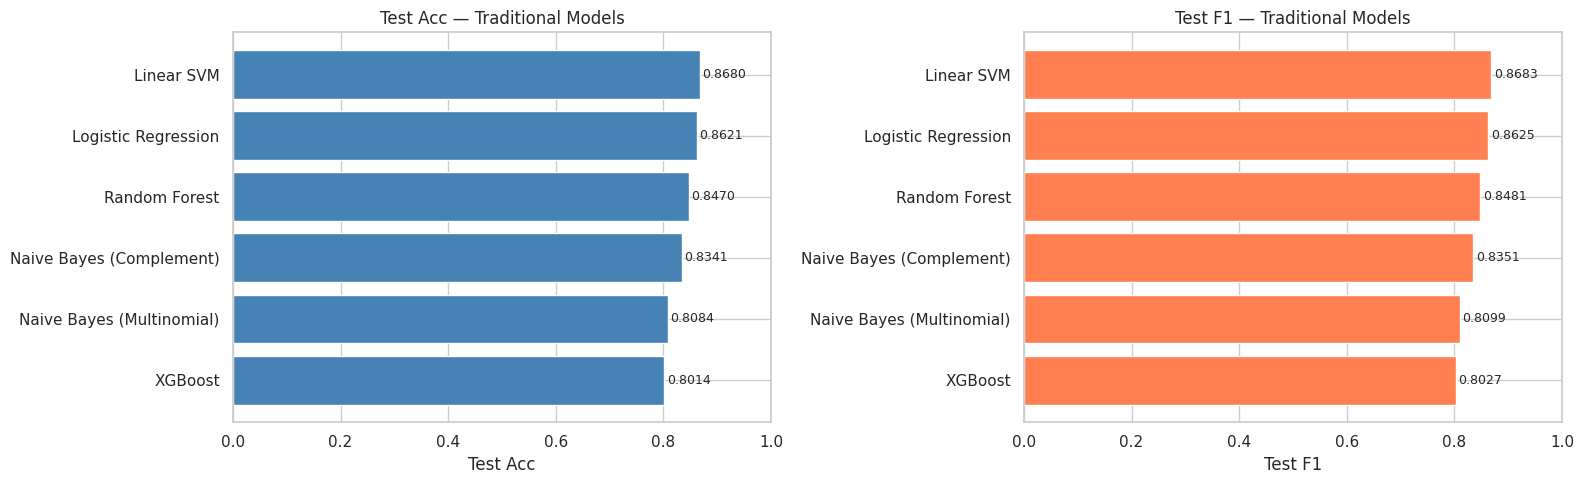

In [ ]:
# ── Bar chart: Test Accuracy & F1 ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, metric, color in zip(axes,
                              ['Test Acc', 'Test F1'],
                              ['steelblue', 'coral']):
    sorted_df = results_df.sort_values(metric)
    bars = ax.barh(sorted_df['Model'], sorted_df[metric], color=color, edgecolor='white')
    ax.set_xlim(0, 1)
    ax.set_xlabel(metric)
    ax.set_title(f'{metric} — Traditional Models')
    for bar, val in zip(bars, sorted_df[metric]):
        ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('traditional_ml_comparison.png')
plt.show()

## 5. Best Model — Detailed Analysis

In [ ]:
# ── Pick best model by Test F1 ────────────────────────────────────────────────
best_name = results_df.iloc[0]['Model']
best_model = MODELS[best_name]
y_test_pred = best_model.predict(X_test_tfidf)

print(f'Best Model: {best_name}')
print('\n=== Classification Report (Test Set) ===')
print(classification_report(y_test, y_test_pred, target_names=LABEL_NAMES))

Best Model: Linear SVM

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

    negative       0.92      0.88      0.90       273
     neutral       0.85      0.85      0.85       283
    positive       0.84      0.88      0.86       300

    accuracy                           0.87       856
   macro avg       0.87      0.87      0.87       856
weighted avg       0.87      0.87      0.87       856



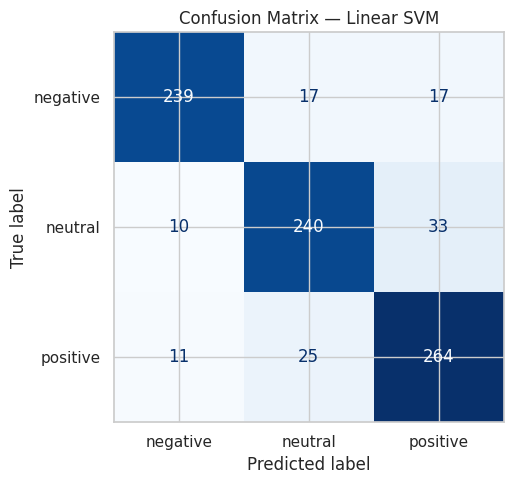

In [ ]:
# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.savefig('confusion_matrix_best_trad.png')
plt.show()

In [ ]:
# ── 5-Fold Cross-Validation on Train+Val ─────────────────────────────────────
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(
    TfidfVectorizer(ngram_range=(1,2), max_features=20000, sublinear_tf=True, min_df=2),
    MODELS[best_name]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X_trainval, y_trainval,
                             cv=cv, scoring='f1_weighted', n_jobs=-1)

print(f'5-Fold CV F1 (weighted): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
print(f'Individual folds: {cv_scores.round(4)}')

5-Fold CV F1 (weighted): 0.8576 ± 0.0066
Individual folds: [0.858  0.8623 0.8553 0.8467 0.8659]


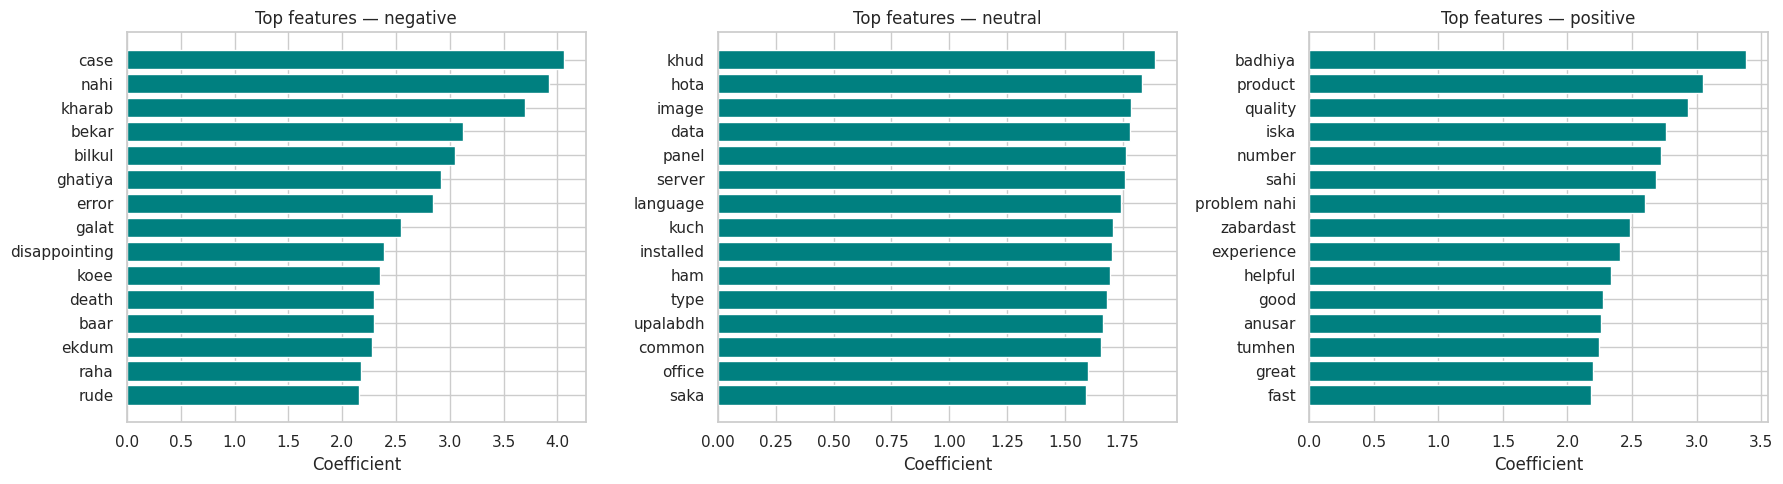

In [ ]:
# ── Top TF-IDF features per class (Logistic Regression) ──────────────────────
if 'Logistic Regression' in MODELS:
    lr = MODELS['Logistic Regression']
    feature_names = np.array(tfidf.get_feature_names_out())

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for idx, (ax, label_name) in enumerate(zip(axes, LABEL_NAMES)):
        coefs = lr.coef_[idx]
        top_idx = np.argsort(coefs)[-15:]
        ax.barh(feature_names[top_idx], coefs[top_idx], color='teal')
        ax.set_title(f'Top features — {label_name}')
        ax.set_xlabel('Coefficient')
    plt.tight_layout()
    plt.savefig('top_features_logreg.png')
    plt.show()

## 6. Save Results

In [ ]:
results_df.to_csv('/content/drive/MyDrive/data/traditional_ml_results.csv', index=False)
print('Results saved → traditional_ml_results.csv ✓')
print('\n➡ Proceed to Notebook 3 for Transformer-based models.')

Results saved → traditional_ml_results.csv ✓

➡ Proceed to Notebook 3 for Transformer-based models.


In [ ]:
## 7. Save Best Model for Interface

import joblib
import os

# Ensure the local 'models' directory exists before saving anything locally
os.makedirs('models', exist_ok=True)

# Best model is Linear SVM based on your results
# Load from the correct path in Google Drive
best_model_for_interface = joblib.load(f'{DRIVE_MODELS_DIR}/Linear_SVM.pkl')

# Save the best model to the local 'models' directory
joblib.dump(best_model_for_interface, 'models/best_model.pkl')

# The tfidf vectorizer is already in memory and was also saved to DRIVE_MODELS_DIR
# We will use the in-memory 'tfidf' object and save it to the local 'models' directory.
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')

# Also copy to Drive so it persists after Colab session ends
import shutil
shutil.copy('models/best_model.pkl',       '/content/drive/MyDrive/data/best_model.pkl')
shutil.copy('models/tfidf_vectorizer.pkl', '/content/drive/MyDrive/data/tfidf_vectorizer.pkl')

print('Best model (Linear SVM) saved ✓')
print('TF-IDF vectorizer saved ✓')
print('Both copied to Google Drive ✓')

Best model (Linear SVM) saved ✓
TF-IDF vectorizer saved ✓
Both copied to Google Drive ✓
